<a href="https://colab.research.google.com/github/ErfanS99/exercise1-rl-fundamentals-RL2026/blob/main/RL_Ex1_Colab_Workspace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

# Return to Colab's main directory
%cd /content

# Clone your personal GitHub fork
!git clone https://github.com/ErfanS99/exercise1-rl-fundamentals-RL2026.git

# Enter the new repository
%cd /content/exercise1-rl-fundamentals-RL2026

# Check which GitHub repository is connected
!git remote -v


/content
Cloning into 'exercise1-rl-fundamentals-RL2026'...
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 11 (delta 0), reused 11 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (11/11), 743.00 KiB | 5.09 MiB/s, done.
/content/exercise1-rl-fundamentals-RL2026
origin	https://github.com/ErfanS99/exercise1-rl-fundamentals-RL2026.git (fetch)
origin	https://github.com/ErfanS99/exercise1-rl-fundamentals-RL2026.git (push)


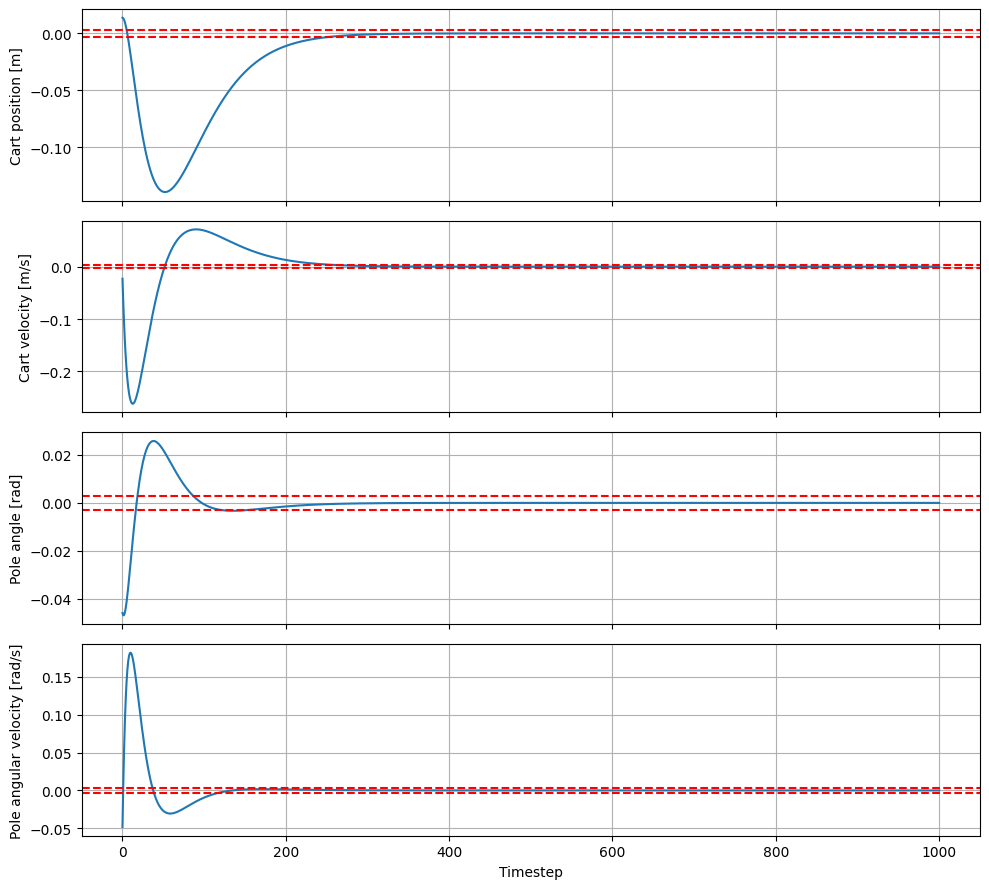

Executed timesteps: 1000


In [7]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

from cartpole_lqr import (
    linerized_cartpole_system,
    optimal_controller,
    apply_state_controller
)

# Create environment with a 1000-step limit
env = gym.make("CartPole-v1", max_episode_steps=1000)

# Get physical parameters and LQR controller
pole = env.unwrapped
A, B = linerized_cartpole_system(
    pole.masspole, pole.masscart,
    pole.length, pole.gravity
)
K = optimal_controller(A, B)

# Initialize the simulation
obs, _ = env.reset(seed=0)
states = [obs.copy()]

# Run the LQR controller for up to 1000 timesteps
for i in range(1000):

    # Compute the control action and force
    action, force = apply_state_controller(K, obs)

    # Limit force magnitude to 10 N
    env.unwrapped.force_mag = abs(
        float(np.clip(force, -10, 10))
    )

    # Apply the action
    obs, reward, terminated, truncated, _ = env.step(action)

    # Store the new observation
    states.append(obs.copy())

    if terminated or truncated:
        break

env.close()

states = np.array(states)

# Plot the four states
labels = [
    "Cart position [m]",
    "Cart velocity [m/s]",
    "Pole angle [rad]",
    "Pole angular velocity [rad/s]"
]

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)

for j, ax in enumerate(axes):
    ax.plot(np.arange(len(states)), states[:, j])
    ax.axhline(0.003, color="red", linestyle="--")
    ax.axhline(-0.003, color="red", linestyle="--")
    ax.set_ylabel(labels[j])
    ax.grid(True)

axes[-1].set_xlabel("Timestep")
plt.tight_layout()
plt.show()

print("Executed timesteps:", len(states) - 1)
